In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [3]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [4]:
class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

In [5]:

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First Convolutional Layer
    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),

    # First Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolutional Layer
    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),

    # Second Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output Layer
    tf.keras.layers.Dense(10, activation='softmax')
])

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8153 - loss: 0.5111 - val_accuracy: 0.8593 - val_loss: 0.3916
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8787 - loss: 0.3367 - val_accuracy: 0.8767 - val_loss: 0.3284
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8934 - loss: 0.2908 - val_accuracy: 0.8911 - val_loss: 0.2992
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9049 - loss: 0.2583 - val_accuracy: 0.8897 - val_loss: 0.2992
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9142 - loss: 0.2315 - val_accuracy: 0.9025 - val_loss: 0.2642


In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8982 - loss: 0.2786
Test Loss: 0.2786133289337158
Test Accuracy: 89.819997549057 %


In [9]:
predictions = model.predict(x_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

print("Predicted Labels:")
print(predicted_labels)

print("\nActual Labels:")
print(y_test[:5])

print("\nPredicted Clothing Categories:")

for i in range(5):
    print(class_names[predicted_labels[i]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Predicted Labels:
[9 2 1 1 6]

Actual Labels:
[9 2 1 1 6]

Predicted Clothing Categories:
Ankle boot
Pullover
Trouser
Trouser
Shirt


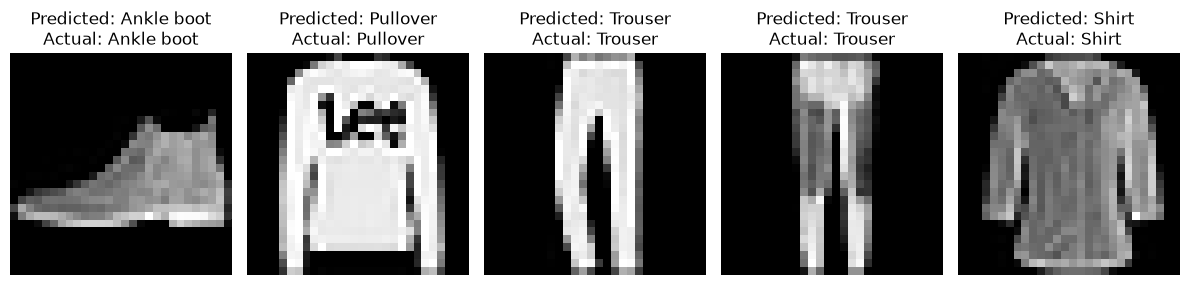

In [10]:
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    predicted = class_names[predicted_labels[i]]
    actual = class_names[y_test[i]]

    plt.title(
        f"Predicted: {predicted}\nActual: {actual}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:
# Implement a CNN model to classify different clothing categories. Use
# Conv2D, MaxPooling2D, Flatten and Dense layers and predict labels for
# five test images.
# Use Dataset - Fashion-MNIST